In [20]:
pip install wbgapi

                            OLS Regression Results                            
Dep. Variable:               Log(CO2)   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     234.7
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           9.35e-27
Time:                        20:25:19   Log-Likelihood:                 13.358
No. Observations:                  55   AIC:                            -20.72
Df Residuals:                      52   BIC:                            -14.69
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.7029 

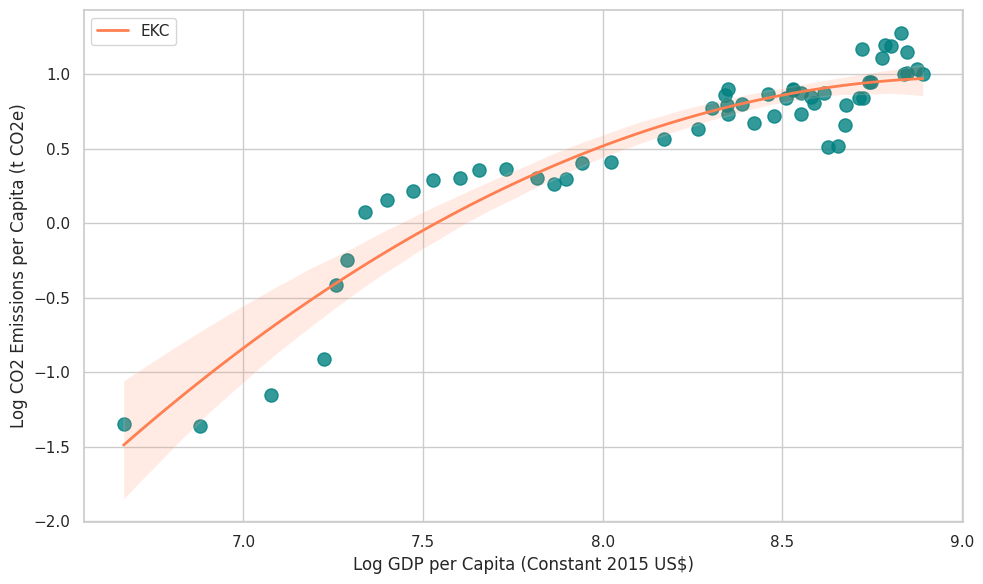

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import wbgapi as wb

country = "BWA"
years = range(1970, 2025)

gdp_series = wb.data.DataFrame(
    "NY.GDP.PCAP.KD", country, years, numericTimeKeys=True
).squeeze()
co2_series = wb.data.DataFrame(
    "EN.GHG.CO2.PC.CE.AR5", country, years, numericTimeKeys=True
).squeeze()

df = pd.DataFrame({
    "GDP pc": gdp_series,
    "CO2 pc": co2_series,
})
df.index.name = "Year"

df["Log(GDP pc)"] = np.log(df["GDP pc"])
df["Log(CO2)"] = np.log(df["CO2 pc"])

df["Log(GDP pc) centered"] = df["Log(GDP pc)"] - df["Log(GDP pc)"].mean()
df["Log(GDP square)"] = df["Log(GDP pc) centered"] ** 2

X = df[["Log(GDP pc) centered", "Log(GDP square)"]]
X = sm.add_constant(X)
y = df["Log(CO2)"]

regression_model = sm.OLS(y, X).fit()

print(regression_model.summary())

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.regplot(
    data=df.reset_index(),
    x="Log(GDP pc)",
    y="Log(CO2)",
    order=2,
    color="teal",
    marker="o",
    scatter_kws={"s": 90, "alpha": 0.8},
    line_kws={"color": "coral", "linewidth": 2, "label": "EKC"},
)

plt.xlabel("Log GDP per Capita (Constant 2015 US$)", fontsize=12)
plt.ylabel("Log CO2 Emissions per Capita (t CO2e)", fontsize=12)
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()